# A9 — Optimize Dense model for lower MAE\_cm

This notebook keeps the same MLflow setup, paths, and general data pipeline as the earlier notebooks.

Goal:
- optimize the Dense model
- reduce mean CV test MAE in cm
- test not only architecture and hyperparameters, but also data handling choices

Optimization dimensions tested:
- hidden layer sizes
- dropout
- optimizer
- learning rate
- batch size
- loss function
- sequence length
- stride
- input feature engineering
- target scaling
- target clipping

## Imports and shared configuration

In [8]:
from pathlib import Path
import os
import random
import warnings
import copy
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import mlflow
import mlflow.pytorch
from mlflow.tracking import MlflowClient

from dotenv import load_dotenv
from os import getenv


warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# Shared experiment settings
SEQ_LEN = 20
STRIDE = 1
N_SPLITS = 5
VALIDATION_SPLIT = 0.10

BATCH_SIZE = 32
EPOCHS = 100
PATIENCE = 10
LEARNING_RATE = 1e-3

LOSS_NAME = "mse"
DEFAULT_OPTIMIZER = "adam"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Keep the same path style as your previous notebook
DATA_DIR = Path("../../data/raw/kinect_good_preprocessed")

# Reporting / artifact paths
output_dir = Path("reporting/results")
output_dir.mkdir(parents=True, exist_ok=True)

artifact_dir = Path("reporting/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

JOINTS = [
    "head",
    "left_shoulder",
    "left_elbow",
    "right_shoulder",
    "right_elbow",
    "left_hand",
    "right_hand",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_foot",
    "right_foot",
]

INPUT_FEATURES = [f"{j}_{axis}" for j in JOINTS for axis in ["x", "y"]]
TARGET_FEATURES = [f"{j}_z" for j in JOINTS]

FRAME_COL_CANDIDATES = ["FrameNo", "frame", "frame_no", "Frame", "frameno"]
SEQUENCE_COL_CANDIDATES = ["sequence_id", "SequenceId", "movement_id", "MovementId", "id", "ID"]

# Set this based on your raw z-values
TARGET_UNIT = "meters"

def to_cm(value):
    if TARGET_UNIT == "meters":
        return value * 100.0
    return value

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)
print("Input features:", len(INPUT_FEATURES))
print("Target features:", len(TARGET_FEATURES))

PyTorch version: 2.11.0+cpu
Device: cpu
Input features: 26
Target features: 13


## MLFlow setup

In [9]:
load_dotenv("../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix env path/variable.")

EXPERIMENT_NAME = "A9_dense_conv1d_depth_regression"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

client = MlflowClient()

MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A9_dense_conv1d_depth_regression


## Helper functions

In [10]:
def read_table_file(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".tsv":
        return pd.read_csv(path, sep="\t")
    if suffix == ".txt":
        try:
            df = pd.read_csv(path)
            if df.shape[1] > 1:
                return df
        except Exception:
            pass
        return pd.read_csv(path, delim_whitespace=True)
    if suffix in [".xlsx", ".xls"]:
        return pd.read_excel(path)
    if suffix == ".parquet":
        return pd.read_parquet(path)
    raise ValueError(f"Unsupported file type: {path}")


def find_frame_col(df: pd.DataFrame):
    lower_map = {c.lower(): c for c in df.columns}
    for col in FRAME_COL_CANDIDATES:
        if col.lower() in lower_map:
            return lower_map[col.lower()]
    return None


def find_sequence_col(df: pd.DataFrame):
    lower_map = {c.lower(): c for c in df.columns}
    for col in SEQUENCE_COL_CANDIDATES:
        if col.lower() in lower_map:
            return lower_map[col.lower()]
    return None


def standardize_joint_column_names(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    rename_map = {}
    for col in df.columns:
        normalized = col.strip().lower().replace(" ", "_").replace("-", "_")
        rename_map[col] = normalized
    return df.rename(columns=rename_map)

## Load Kinect movement data

In [11]:
def load_kinect_data(data_dir: Path) -> pd.DataFrame:
    if not data_dir.exists():
        raise FileNotFoundError(
            f"DATA_DIR does not exist: {data_dir}\n"
            "Update DATA_DIR in the config cell to your raw Kinect folder."
        )

    files = []
    for pattern in ["*.csv", "*.tsv", "*.txt", "*.xlsx", "*.xls", "*.parquet"]:
        files.extend(sorted(data_dir.glob(pattern)))

    if not files:
        raise FileNotFoundError(
            f"No supported data files found in {data_dir}.\n"
            "Expected csv, tsv, txt, xlsx, xls, or parquet."
        )

    dfs = []
    for file_path in files:
        df = read_table_file(file_path)
        df = standardize_joint_column_names(df)

        seq_col = find_sequence_col(df)
        if seq_col is None:
            df["sequence_id"] = file_path.stem
        elif seq_col != "sequence_id":
            df = df.rename(columns={seq_col: "sequence_id"})

        frame_col = find_frame_col(df)
        if frame_col is None:
            df["frameno"] = np.arange(len(df))
        elif frame_col != "frameno":
            df = df.rename(columns={frame_col: "frameno"})

        dfs.append(df)

    full_df = pd.concat(dfs, ignore_index=True)
    full_df = full_df.sort_values(["sequence_id", "frameno"]).reset_index(drop=True)
    return full_df

df_raw = load_kinect_data(DATA_DIR)

print("Shape:", df_raw.shape)
print("Columns:", len(df_raw.columns))
display(df_raw.head())

missing_inputs = [c for c in INPUT_FEATURES if c not in df_raw.columns]
missing_targets = [c for c in TARGET_FEATURES if c not in df_raw.columns]

print("Missing input columns:", missing_inputs)
print("Missing target columns:", missing_targets)

assert not missing_inputs, "Missing input columns."
assert not missing_targets, "Missing target columns."

Shape: (24005, 41)
Columns: 41


,frameno,head_x,head_y,head_z,left_shoulder_x,left_shoulder_y,left_shoulder_z,left_elbow_x,left_elbow_y,left_elbow_z,...,right_knee_x,right_knee_y,right_knee_z,left_foot_x,left_foot_y,left_foot_z,right_foot_x,right_foot_y,right_foot_z,sequence_id
0,3,-0.016480,0.77960,0.070646,-0.16221,0.58030,0.047752,-0.23056,0.84519,-0.033909,...,0.13624,-0.51948,0.003528,-0.13975,-0.86193,-0.025068,0.15162,-0.91701,-0.005627,A100_kinect
1,4,-0.016990,0.77937,0.069989,-0.16242,0.58031,0.047168,-0.23050,0.84547,-0.034061,...,0.13663,-0.51921,0.003291,-0.13982,-0.86208,-0.024980,0.15001,-0.91352,-0.001491,A100_kinect
2,5,-0.017345,0.77928,0.069703,-0.16258,0.58039,0.046964,-0.23044,0.84564,-0.034175,...,0.13633,-0.51957,0.003223,-0.13937,-0.86233,-0.024777,0.14981,-0.91385,-0.001252,A100_kinect
3,6,-0.017602,0.77935,0.069520,-0.16276,0.58035,0.046524,-0.23037,0.84598,-0.034318,...,0.13653,-0.51892,0.002961,-0.13907,-0.86225,-0.024431,0.15711,-0.92048,-0.014920,A100_kinect
4,7,-0.017559,0.77938,0.069530,-0.16279,0.58030,0.046288,-0.22906,0.85070,-0.036518,...,0.13662,-0.51940,0.002998,-0.13917,-0.86364,-0.025274,0.15212,-0.91871,-0.004539,A100_kinect


Missing input columns: []
Missing target columns: []


### Build fixed-length sequences

In [12]:
def build_sequences(
    df: pd.DataFrame,
    input_cols,
    target_cols,
    seq_len: int = 20,
    stride: int = 1,
):
    X_list = []
    y_list = []
    seq_ids = []

    clean_df = df.dropna(subset=input_cols + target_cols).copy()

    for seq_id, group in clean_df.groupby("sequence_id"):
        group = group.sort_values("frameno").reset_index(drop=True)

        x_values = group[input_cols].to_numpy(dtype=np.float32)
        y_values = group[target_cols].to_numpy(dtype=np.float32)

        if len(group) < seq_len:
            continue

        for start in range(0, len(group) - seq_len + 1, stride):
            end = start + seq_len
            X_list.append(x_values[start:end])
            y_list.append(y_values[start:end])
            seq_ids.append(seq_id)

    X = np.array(X_list, dtype=np.float32)
    y = np.array(y_list, dtype=np.float32)
    seq_ids = np.array(seq_ids)

    return X, y, seq_ids

X, y, seq_ids = build_sequences(
    df=df_raw,
    input_cols=INPUT_FEATURES,
    target_cols=TARGET_FEATURES,
    seq_len=SEQ_LEN,
    stride=STRIDE,
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("seq_ids shape:", seq_ids.shape)

X shape: (20604, 20, 26)
y shape: (20604, 20, 13)
seq_ids shape: (20604,)


### Dataset and scaling helpers

In [13]:
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]
    
def fit_scaler_on_training_sequences(X_train):
    scaler = StandardScaler()
    X_train_2d = X_train.reshape(-1, X_train.shape[-1])
    scaler.fit(X_train_2d)
    return scaler


def transform_sequences(X_data, scaler):
    X_2d = X_data.reshape(-1, X_data.shape[-1])
    X_scaled = scaler.transform(X_2d).reshape(X_data.shape).astype(np.float32)
    return X_scaled

## Define Deep Learning models

In [14]:
class DenseDepthRegressor(nn.Module):
    def __init__(self, seq_len, n_features, n_targets, hidden_units=(256, 128), dropout_rate=0.0):
        super().__init__()
        input_dim = seq_len * n_features
        output_dim = seq_len * n_targets

        layers_list = []
        prev_dim = input_dim

        for units in hidden_units:
            layers_list.append(nn.Linear(prev_dim, units))
            layers_list.append(nn.ReLU())
            if dropout_rate > 0:
                layers_list.append(nn.Dropout(dropout_rate))
            prev_dim = units

        layers_list.append(nn.Linear(prev_dim, output_dim))
        self.network = nn.Sequential(*layers_list)

        self.seq_len = seq_len
        self.n_targets = n_targets

    def forward(self, x):
        batch_size = x.shape[0]
        x = x.reshape(batch_size, -1)
        out = self.network(x)
        out = out.reshape(batch_size, self.seq_len, self.n_targets)
        return out
    
class Conv1DDepthRegressor(nn.Module):
    def __init__(self, n_features, n_targets, filters=(64, 128), kernel_size=3, dropout_rate=0.0):
        super().__init__()

        conv_layers = []
        in_channels = n_features

        for f in filters:
            conv_layers.append(nn.Conv1d(in_channels, f, kernel_size=kernel_size, padding="same"))
            conv_layers.append(nn.ReLU())
            if dropout_rate > 0:
                conv_layers.append(nn.Dropout(dropout_rate))
            in_channels = f

        self.feature_extractor = nn.Sequential(*conv_layers)
        self.output_layer = nn.Conv1d(in_channels, n_targets, kernel_size=1)

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.feature_extractor(x)
        x = self.output_layer(x)
        x = x.transpose(1, 2)
        return x
    

def build_model(model_family, config):
    if model_family == "Dense":
        return DenseDepthRegressor(
            seq_len=SEQ_LEN,
            n_features=len(INPUT_FEATURES),
            n_targets=len(TARGET_FEATURES),
            hidden_units=config["hidden_units"],
            dropout_rate=config.get("dropout_rate", 0.0),
        )
    elif model_family == "Conv1D":
        return Conv1DDepthRegressor(
            n_features=len(INPUT_FEATURES),
            n_targets=len(TARGET_FEATURES),
            filters=config["filters"],
            kernel_size=config["kernel_size"],
            dropout_rate=config.get("dropout_rate", 0.0),
        )
    else:
        raise ValueError(f"Unknown model_family: {model_family}")

### Training and evaluation helpers

In [15]:
def get_optimizer(model, optimizer_name="adam", lr=LEARNING_RATE):
    if optimizer_name.lower() == "adam":
        return torch.optim.Adam(model.parameters(), lr=lr)
    elif optimizer_name.lower() == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_name}")
    
def evaluate_loss(model, data_loader, criterion):
    model.eval()
    total_loss = 0.0
    n_samples = 0

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            preds = model(X_batch)
            loss = criterion(preds, y_batch)

            batch_size = X_batch.size(0)
            total_loss += loss.item() * batch_size
            n_samples += batch_size

    return total_loss / max(n_samples, 1)


def predict_model(model, data_loader):
    model.eval()
    preds_all = []
    targets_all = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(DEVICE)
            preds = model(X_batch).cpu().numpy()
            preds_all.append(preds)
            targets_all.append(y_batch.numpy())

    y_pred = np.concatenate(preds_all, axis=0)
    y_true = np.concatenate(targets_all, axis=0)
    return y_true, y_pred


def per_joint_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred), axis=(0, 1))

def train_model(
    model,
    train_loader,
    val_loader,
    optimizer_name="adam",
    lr=LEARNING_RATE,
    epochs=EPOCHS,
    patience=PATIENCE,
):
    model = model.to(DEVICE)
    criterion = nn.MSELoss()
    optimizer = get_optimizer(model, optimizer_name=optimizer_name, lr=lr)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_mae": [],
        "val_mae": [],
    }

    best_model_state = copy.deepcopy(model.state_dict())
    best_val_loss = float("inf")
    best_epoch = 0
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        total_train_loss = 0.0
        total_train_mae = 0.0
        n_train = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()
            preds = model(X_batch)
            loss = criterion(preds, y_batch)
            loss.backward()
            optimizer.step()

            batch_size = X_batch.size(0)
            total_train_loss += loss.item() * batch_size
            total_train_mae += torch.mean(torch.abs(preds - y_batch)).item() * batch_size
            n_train += batch_size

        train_loss = total_train_loss / max(n_train, 1)
        train_mae = total_train_mae / max(n_train, 1)

        val_loss = evaluate_loss(model, val_loader, criterion)

        model.eval()
        total_val_mae = 0.0
        n_val = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)
                preds = model(X_batch)
                batch_size = X_batch.size(0)
                total_val_mae += torch.mean(torch.abs(preds - y_batch)).item() * batch_size
                n_val += batch_size
        val_mae = total_val_mae / max(n_val, 1)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_mae"].append(train_mae)
        history["val_mae"].append(val_mae)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    model.load_state_dict(best_model_state)
    return model, history, best_val_loss, best_epoch

### A small data-quality check before optimization.

In [16]:
quality_summary = pd.DataFrame({
    "missing_count": df_raw[INPUT_FEATURES + TARGET_FEATURES].isna().sum(),
    "missing_ratio": df_raw[INPUT_FEATURES + TARGET_FEATURES].isna().mean(),
    "std": df_raw[INPUT_FEATURES + TARGET_FEATURES].std(),
    "min": df_raw[INPUT_FEATURES + TARGET_FEATURES].min(),
    "max": df_raw[INPUT_FEATURES + TARGET_FEATURES].max(),
}).sort_values("missing_ratio", ascending=False)

display(quality_summary.head(20))

,missing_count,missing_ratio,std,min,max
head_x,0,0.0,0.028541,-0.219620,0.227100
head_y,0,0.0,0.273669,-0.286400,0.866600
left_shoulder_x,0,0.0,0.027117,-0.315020,0.057288
left_shoulder_y,0,0.0,0.264003,-0.430780,0.669560
left_elbow_x,0,0.0,0.058499,-0.479500,-0.008361
left_elbow_y,0,0.0,0.286714,-0.271150,0.923650
right_shoulder_x,0,0.0,0.030649,0.013050,0.325720
right_shoulder_y,0,0.0,0.259287,-0.393830,0.650950
right_elbow_x,0,0.0,0.061773,0.101260,0.487550
right_elbow_y,0,0.0,0.281324,-0.232920,0.898130


## Optimization helpers

The next cells add:
- optional velocity features
- optional target scaling
- optional target clipping
- flexible sequence length / stride
- flexible Dense training settings

### Data-handling helpers

In [17]:
def add_velocity_features(df: pd.DataFrame, input_cols):
    df = df.copy()
    velocity_cols = []

    for col in input_cols:
        new_col = f"{col}_vel"
        df[new_col] = df.groupby("sequence_id")[col].diff().fillna(0.0)
        velocity_cols.append(new_col)

    return df, velocity_cols


def clip_targets_by_quantile(df: pd.DataFrame, target_cols, lower_q=0.01, upper_q=0.99):
    df = df.copy()
    clip_info = {}

    for col in target_cols:
        lo = df[col].quantile(lower_q)
        hi = df[col].quantile(upper_q)
        df[col] = df[col].clip(lo, hi)
        clip_info[col] = {"lower": float(lo), "upper": float(hi)}

    return df, clip_info


def fit_target_scaler_on_training_sequences(y_train):
    scaler = StandardScaler()
    y_train_2d = y_train.reshape(-1, y_train.shape[-1])
    scaler.fit(y_train_2d)
    return scaler


def transform_targets(y_data, scaler):
    y_2d = y_data.reshape(-1, y_data.shape[-1])
    y_scaled = scaler.transform(y_2d).reshape(y_data.shape).astype(np.float32)
    return y_scaled


def inverse_transform_targets(y_data, scaler):
    y_2d = y_data.reshape(-1, y_data.shape[-1])
    y_inv = scaler.inverse_transform(y_2d).reshape(y_data.shape).astype(np.float32)
    return y_inv

### Dense model builder stays Dense-only, but now we can vary activation and dropout

In [18]:
class DenseDepthRegressorFlexible(nn.Module):
    def __init__(
        self,
        seq_len,
        n_features,
        n_targets,
        hidden_units=(256, 128),
        dropout_rate=0.0,
        activation="relu",
    ):
        super().__init__()
        input_dim = seq_len * n_features
        output_dim = seq_len * n_targets

        if activation == "relu":
            act_layer = nn.ReLU
        elif activation == "gelu":
            act_layer = nn.GELU
        elif activation == "leaky_relu":
            act_layer = nn.LeakyReLU
        else:
            raise ValueError(f"Unsupported activation: {activation}")

        layers_list = []
        prev_dim = input_dim

        for units in hidden_units:
            layers_list.append(nn.Linear(prev_dim, units))
            layers_list.append(act_layer())
            if dropout_rate > 0:
                layers_list.append(nn.Dropout(dropout_rate))
            prev_dim = units

        layers_list.append(nn.Linear(prev_dim, output_dim))
        self.network = nn.Sequential(*layers_list)

        self.seq_len = seq_len
        self.n_targets = n_targets

    def forward(self, x):
        batch_size = x.shape[0]
        x = x.reshape(batch_size, -1)
        out = self.network(x)
        out = out.reshape(batch_size, self.seq_len, self.n_targets)
        return out

### Flexible optimizer + loss

In [19]:
def get_optimizer_flexible(model, optimizer_name="adam", lr=1e-3, weight_decay=0.0):
    name = optimizer_name.lower()

    if name == "adam":
        return torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif name == "rmsprop":
        return torch.optim.RMSprop(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_name}")


def get_loss_function(loss_name="mse"):
    name = loss_name.lower()

    if name == "mse":
        return nn.MSELoss()
    elif name == "huber":
        return nn.HuberLoss(delta=1.0)
    elif name == "smoothl1":
        return nn.SmoothL1Loss()
    else:
        raise ValueError(f"Unsupported loss: {loss_name}")

### Training loop with scheduler support.

In [20]:
def train_model_flexible(
    model,
    train_loader,
    val_loader,
    optimizer_name="adam",
    lr=1e-3,
    weight_decay=0.0,
    loss_name="mse",
    epochs=EPOCHS,
    patience=PATIENCE,
    use_scheduler=False,
):
    model = model.to(DEVICE)
    criterion = get_loss_function(loss_name)
    optimizer = get_optimizer_flexible(
        model,
        optimizer_name=optimizer_name,
        lr=lr,
        weight_decay=weight_decay,
    )

    scheduler = None
    if use_scheduler:
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=0.5,
            patience=3,
        )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_mae": [],
        "val_mae": [],
        "lr": [],
    }

    best_model_state = copy.deepcopy(model.state_dict())
    best_val_loss = float("inf")
    best_epoch = 0
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        total_train_loss = 0.0
        total_train_mae = 0.0
        n_train = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()
            preds = model(X_batch)
            loss = criterion(preds, y_batch)
            loss.backward()
            optimizer.step()

            batch_size = X_batch.size(0)
            total_train_loss += loss.item() * batch_size
            total_train_mae += torch.mean(torch.abs(preds - y_batch)).item() * batch_size
            n_train += batch_size

        train_loss = total_train_loss / max(n_train, 1)
        train_mae = total_train_mae / max(n_train, 1)

        model.eval()
        total_val_loss = 0.0
        total_val_mae = 0.0
        n_val = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)

                preds = model(X_batch)
                loss = criterion(preds, y_batch)

                batch_size = X_batch.size(0)
                total_val_loss += loss.item() * batch_size
                total_val_mae += torch.mean(torch.abs(preds - y_batch)).item() * batch_size
                n_val += batch_size

        val_loss = total_val_loss / max(n_val, 1)
        val_mae = total_val_mae / max(n_val, 1)

        if scheduler is not None:
            scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_mae"].append(train_mae)
        history["val_mae"].append(val_mae)
        history["lr"].append(current_lr)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    model.load_state_dict(best_model_state)
    return model, history, best_val_loss, best_epoch

### Build experiment-ready sequences with optional data handling

In [21]:
def prepare_dense_dataset(
    df_raw,
    seq_len,
    stride,
    use_velocity=False,
    clip_targets=False,
    clip_lower_q=0.01,
    clip_upper_q=0.99,
):
    df = df_raw.copy()
    input_cols = INPUT_FEATURES.copy()

    if use_velocity:
        df, velocity_cols = add_velocity_features(df, INPUT_FEATURES)
        input_cols = input_cols + velocity_cols

    clip_info = None
    if clip_targets:
        df, clip_info = clip_targets_by_quantile(
            df,
            TARGET_FEATURES,
            lower_q=clip_lower_q,
            upper_q=clip_upper_q,
        )

    X, y, seq_ids = build_sequences(
        df=df,
        input_cols=input_cols,
        target_cols=TARGET_FEATURES,
        seq_len=seq_len,
        stride=stride,
    )

    return {
        "df": df,
        "input_cols": input_cols,
        "X": X,
        "y": y,
        "seq_ids": seq_ids,
        "clip_info": clip_info,
    }

### Experiment configurations

This is where we test both hyperparameters and data handling.

In [22]:
dense_optimization_configs = [
    {
        "model_variant": "Dense_baseline_256_128",
        "hidden_units": (256, 128),
        "dropout_rate": 0.0,
        "activation": "relu",
        "optimizer": "adam",
        "learning_rate": 1e-3,
        "weight_decay": 0.0,
        "batch_size": 32,
        "loss_name": "mse",
        "use_scheduler": False,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": False,
        "clip_targets": False,
        "scale_targets": False,
    },
    {
        "model_variant": "Dense_wider_512_256_128",
        "hidden_units": (512, 256, 128),
        "dropout_rate": 0.0,
        "activation": "relu",
        "optimizer": "adam",
        "learning_rate": 1e-3,
        "weight_decay": 0.0,
        "batch_size": 32,
        "loss_name": "mse",
        "use_scheduler": False,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": False,
        "clip_targets": False,
        "scale_targets": False,
    },
    {
        "model_variant": "Dense_dropout_256_128_do02",
        "hidden_units": (256, 128),
        "dropout_rate": 0.2,
        "activation": "relu",
        "optimizer": "adam",
        "learning_rate": 1e-3,
        "weight_decay": 0.0,
        "batch_size": 32,
        "loss_name": "mse",
        "use_scheduler": False,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": False,
        "clip_targets": False,
        "scale_targets": False,
    },
    {
        "model_variant": "Dense_adamw_weightdecay",
        "hidden_units": (256, 128),
        "dropout_rate": 0.1,
        "activation": "relu",
        "optimizer": "adamw",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 32,
        "loss_name": "mse",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": False,
        "clip_targets": False,
        "scale_targets": False,
    },
    {
        "model_variant": "Dense_huber_loss",
        "hidden_units": (256, 128),
        "dropout_rate": 0.1,
        "activation": "relu",
        "optimizer": "adam",
        "learning_rate": 1e-3,
        "weight_decay": 0.0,
        "batch_size": 32,
        "loss_name": "huber",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": False,
        "clip_targets": False,
        "scale_targets": False,
    },
    {
        "model_variant": "Dense_seq30",
        "hidden_units": (256, 128),
        "dropout_rate": 0.1,
        "activation": "relu",
        "optimizer": "adam",
        "learning_rate": 1e-3,
        "weight_decay": 0.0,
        "batch_size": 32,
        "loss_name": "mse",
        "use_scheduler": True,
        "seq_len": 30,
        "stride": 1,
        "use_velocity": False,
        "clip_targets": False,
        "scale_targets": False,
    },
    {
        "model_variant": "Dense_stride2",
        "hidden_units": (256, 128),
        "dropout_rate": 0.1,
        "activation": "relu",
        "optimizer": "adam",
        "learning_rate": 1e-3,
        "weight_decay": 0.0,
        "batch_size": 32,
        "loss_name": "mse",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 2,
        "use_velocity": False,
        "clip_targets": False,
        "scale_targets": False,
    },
    {
        "model_variant": "Dense_with_velocity",
        "hidden_units": (256, 128),
        "dropout_rate": 0.1,
        "activation": "relu",
        "optimizer": "adam",
        "learning_rate": 1e-3,
        "weight_decay": 0.0,
        "batch_size": 32,
        "loss_name": "mse",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": True,
        "clip_targets": False,
        "scale_targets": False,
    },
    {
        "model_variant": "Dense_target_scaled",
        "hidden_units": (256, 128),
        "dropout_rate": 0.1,
        "activation": "relu",
        "optimizer": "adam",
        "learning_rate": 1e-3,
        "weight_decay": 0.0,
        "batch_size": 32,
        "loss_name": "mse",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": False,
        "clip_targets": False,
        "scale_targets": True,
    },
    {
        "model_variant": "Dense_clip_targets_1_99",
        "hidden_units": (256, 128),
        "dropout_rate": 0.1,
        "activation": "relu",
        "optimizer": "adam",
        "learning_rate": 1e-3,
        "weight_decay": 0.0,
        "batch_size": 32,
        "loss_name": "mse",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": False,
        "clip_targets": True,
        "clip_lower_q": 0.01,
        "clip_upper_q": 0.99,
        "scale_targets": False,
    },
    {
        "model_variant": "Dense_best_guess_combo",
        "hidden_units": (512, 256, 128),
        "dropout_rate": 0.1,
        "activation": "gelu",
        "optimizer": "adamw",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 32,
        "loss_name": "huber",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": True,
        "clip_targets": False,
        "scale_targets": True,
    },
]

dense_optimization_configs

[{'model_variant': 'Dense_baseline_256_128',
  'hidden_units': (256, 128),
  'dropout_rate': 0.0,
  'activation': 'relu',
  'optimizer': 'adam',
  'learning_rate': 0.001,
  'weight_decay': 0.0,
  'batch_size': 32,
  'loss_name': 'mse',
  'use_scheduler': False,
  'seq_len': 20,
  'stride': 1,
  'use_velocity': False,
  'clip_targets': False,
  'scale_targets': False},
 {'model_variant': 'Dense_wider_512_256_128',
  'hidden_units': (512, 256, 128),
  'dropout_rate': 0.0,
  'activation': 'relu',
  'optimizer': 'adam',
  'learning_rate': 0.001,
  'weight_decay': 0.0,
  'batch_size': 32,
  'loss_name': 'mse',
  'use_scheduler': False,
  'seq_len': 20,
  'stride': 1,
  'use_velocity': False,
  'clip_targets': False,
  'scale_targets': False},
 {'model_variant': 'Dense_dropout_256_128_do02',
  'hidden_units': (256, 128),
  'dropout_rate': 0.2,
  'activation': 'relu',
  'optimizer': 'adam',
  'learning_rate': 0.001,
  'weight_decay': 0.0,
  'batch_size': 32,
  'loss_name': 'mse',
  'use_sched

### Main CV runner for Dense optimization

In [23]:
def run_dense_cv_experiment(df_raw, config):
    prepared = prepare_dense_dataset(
        df_raw=df_raw,
        seq_len=config["seq_len"],
        stride=config["stride"],
        use_velocity=config.get("use_velocity", False),
        clip_targets=config.get("clip_targets", False),
        clip_lower_q=config.get("clip_lower_q", 0.01),
        clip_upper_q=config.get("clip_upper_q", 0.99),
    )

    X = prepared["X"]
    y = prepared["y"]
    seq_ids = prepared["seq_ids"]
    input_cols = prepared["input_cols"]

    gkf = GroupKFold(n_splits=N_SPLITS)

    fold_results = []
    fold_histories = []

    with mlflow.start_run(run_name=config["model_variant"], nested=False):
        mlflow.log_param("model_family", "Dense")
        mlflow.log_param("model_variant", config["model_variant"])
        mlflow.log_param("sequence_length", config["seq_len"])
        mlflow.log_param("stride", config["stride"])
        mlflow.log_param("n_splits", N_SPLITS)
        mlflow.log_param("batch_size", config["batch_size"])
        mlflow.log_param("epochs", EPOCHS)
        mlflow.log_param("patience", PATIENCE)
        mlflow.log_param("learning_rate", config["learning_rate"])
        mlflow.log_param("optimizer", config["optimizer"])
        mlflow.log_param("loss", config["loss_name"])
        mlflow.log_param("target_unit", TARGET_UNIT)
        mlflow.log_param("hidden_units", str(config["hidden_units"]))
        mlflow.log_param("dropout_rate", config["dropout_rate"])
        mlflow.log_param("activation", config["activation"])
        mlflow.log_param("weight_decay", config["weight_decay"])
        mlflow.log_param("use_scheduler", config["use_scheduler"])
        mlflow.log_param("use_velocity", config.get("use_velocity", False))
        mlflow.log_param("clip_targets", config.get("clip_targets", False))
        mlflow.log_param("scale_targets", config.get("scale_targets", False))
        mlflow.log_param("n_input_features", len(input_cols))

        for fold_idx, (train_val_idx, test_idx) in enumerate(gkf.split(X, y, groups=seq_ids), start=1):
            X_train_val = X[train_val_idx]
            y_train_val = y[train_val_idx]
            seq_train_val = seq_ids[train_val_idx]

            X_test = X[test_idx]
            y_test = y[test_idx]

            unique_train_sequences = np.unique(seq_train_val)
            train_seq_ids, val_seq_ids = train_test_split(
                unique_train_sequences,
                test_size=VALIDATION_SPLIT,
                random_state=RANDOM_SEED + fold_idx,
            )

            train_mask = np.isin(seq_train_val, train_seq_ids)
            val_mask = np.isin(seq_train_val, val_seq_ids)

            X_train = X_train_val[train_mask]
            y_train = y_train_val[train_mask]
            X_val = X_train_val[val_mask]
            y_val = y_train_val[val_mask]

            x_scaler = fit_scaler_on_training_sequences(X_train)
            X_train_scaled = transform_sequences(X_train, x_scaler)
            X_val_scaled = transform_sequences(X_val, x_scaler)
            X_test_scaled = transform_sequences(X_test, x_scaler)

            y_scaler = None
            if config.get("scale_targets", False):
                y_scaler = fit_target_scaler_on_training_sequences(y_train)
                y_train_scaled = transform_targets(y_train, y_scaler)
                y_val_scaled = transform_targets(y_val, y_scaler)
            else:
                y_train_scaled = y_train.astype(np.float32)
                y_val_scaled = y_val.astype(np.float32)

            train_dataset = SequenceDataset(X_train_scaled, y_train_scaled)
            val_dataset = SequenceDataset(X_val_scaled, y_val_scaled)
            test_dataset = SequenceDataset(X_test_scaled, y_test.astype(np.float32))

            train_loader = DataLoader(train_dataset, batch_size=config["batch_size"], shuffle=True)
            val_loader = DataLoader(val_dataset, batch_size=config["batch_size"], shuffle=False)
            test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)

            model = DenseDepthRegressorFlexible(
                seq_len=config["seq_len"],
                n_features=len(input_cols),
                n_targets=len(TARGET_FEATURES),
                hidden_units=config["hidden_units"],
                dropout_rate=config["dropout_rate"],
                activation=config["activation"],
            )

            trained_model, history, best_val_loss, best_epoch = train_model_flexible(
                model=model,
                train_loader=train_loader,
                val_loader=val_loader,
                optimizer_name=config["optimizer"],
                lr=config["learning_rate"],
                weight_decay=config["weight_decay"],
                loss_name=config["loss_name"],
                epochs=EPOCHS,
                patience=PATIENCE,
                use_scheduler=config["use_scheduler"],
            )

            y_true, y_pred = predict_model(trained_model, test_loader)

            if y_scaler is not None:
                y_pred = inverse_transform_targets(y_pred, y_scaler)

            test_mae = mean_absolute_error(
                y_true.reshape(-1, y_true.shape[-1]),
                y_pred.reshape(-1, y_pred.shape[-1]),
            )
            test_mae_cm = to_cm(test_mae)

            joint_errors = per_joint_mae(y_true, y_pred)
            joint_errors_cm = [to_cm(v) for v in joint_errors]

            mlflow.log_metric(f"fold_{fold_idx}_test_mae", float(test_mae))
            mlflow.log_metric(f"fold_{fold_idx}_test_mae_cm", float(test_mae_cm))
            mlflow.log_metric(f"fold_{fold_idx}_best_val_loss", float(best_val_loss))
            mlflow.log_metric(f"fold_{fold_idx}_best_epoch", int(best_epoch))

            fold_result = {
                "fold": fold_idx,
                "model_family": "Dense",
                "model_variant": config["model_variant"],
                "test_mae": float(test_mae),
                "test_mae_cm": float(test_mae_cm),
                "best_val_loss": float(best_val_loss),
                "best_epoch": int(best_epoch),
                "seq_len": config["seq_len"],
                "stride": config["stride"],
                "use_velocity": config.get("use_velocity", False),
                "clip_targets": config.get("clip_targets", False),
                "scale_targets": config.get("scale_targets", False),
                "batch_size": config["batch_size"],
                "optimizer": config["optimizer"],
                "learning_rate": config["learning_rate"],
                "loss_name": config["loss_name"],
                "n_train_sequences": int(len(X_train)),
                "n_val_sequences": int(len(X_val)),
                "n_test_sequences": int(len(X_test)),
                "joint_mae_cm": joint_errors_cm,
            }

            fold_results.append(fold_result)
            fold_histories.append(history)

        fold_df = pd.DataFrame(fold_results)

        mlflow.log_metric("mean_test_mae", float(fold_df["test_mae"].mean()))
        mlflow.log_metric("std_test_mae", float(fold_df["test_mae"].std()))
        mlflow.log_metric("mean_test_mae_cm", float(fold_df["test_mae_cm"].mean()))
        mlflow.log_metric("std_test_mae_cm", float(fold_df["test_mae_cm"].std()))
        mlflow.log_metric("mean_best_val_loss", float(fold_df["best_val_loss"].mean()))
        mlflow.log_metric("mean_best_epoch", float(fold_df["best_epoch"].mean()))

    return fold_results, fold_histories

### Run all optimization experiments

In [25]:
all_dense_fold_results = []
all_dense_histories = {}

for config in dense_optimization_configs:
    print(f"Running {config['model_variant']} ...")
    fold_results, fold_histories = run_dense_cv_experiment(df_raw, config)
    all_dense_fold_results.extend(fold_results)
    all_dense_histories[config["model_variant"]] = fold_histories

dense_results_folds = pd.DataFrame(all_dense_fold_results)
display(dense_results_folds.head())

Running Dense_baseline_256_128 ...
🏃 View run Dense_baseline_256_128 at: https://172.27.62.170:5001/#/experiments/22/runs/530a10268ef843ba94628376c1590fea
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Dense_wider_512_256_128 ...
🏃 View run Dense_wider_512_256_128 at: https://172.27.62.170:5001/#/experiments/22/runs/0436fdb9e7b944d6bf8c010a547330f7
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Dense_dropout_256_128_do02 ...
🏃 View run Dense_dropout_256_128_do02 at: https://172.27.62.170:5001/#/experiments/22/runs/4c700160583747718c49365456d1443e
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Dense_adamw_weightdecay ...
🏃 View run Dense_adamw_weightdecay at: https://172.27.62.170:5001/#/experiments/22/runs/b94dfb6274ef4428aa34ea50d31448d3
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Dense_huber_loss ...
🏃 View run Dense_huber_loss at: https://172.27.62.170:5001/#/experiments/22

,fold,model_family,model_variant,test_mae,test_mae_cm,best_val_loss,best_epoch,seq_len,stride,use_velocity,clip_targets,scale_targets,batch_size,optimizer,learning_rate,loss_name,n_train_sequences,n_val_sequences,n_test_sequences,joint_mae_cm
0,1,Dense,Dense_baseline_256_128,0.044884,4.488397,0.001061,24,20,1,False,False,False,32,adam,0.001,mse,14847,1626,4131,"[4.589423, 3.7809849, 4.531979, 4.239466, 5.03..."
1,2,Dense,Dense_baseline_256_128,0.037328,3.732846,0.002597,5,20,1,False,False,False,32,adam,0.001,mse,14929,1546,4129,"[3.3365626, 2.8958077, 3.92724, 3.267265, 4.37..."
2,3,Dense,Dense_baseline_256_128,0.029945,2.994466,0.002020,23,20,1,False,False,False,32,adam,0.001,mse,14733,1747,4124,"[2.813876, 2.1448796, 3.0652542, 2.2237945, 2...."
3,4,Dense,Dense_baseline_256_128,0.040279,4.027929,0.003518,9,20,1,False,False,False,32,adam,0.001,mse,14916,1564,4124,"[3.6213665, 3.3589153, 5.0090017, 3.2585752, 4..."
4,5,Dense,Dense_baseline_256_128,0.034099,3.409918,0.002205,17,20,1,False,False,False,32,adam,0.001,mse,14707,1801,4096,"[3.577862, 2.8332148, 3.4447784, 3.2427628, 4...."


### Summary table

In [26]:
dense_results_summary = (
    dense_results_folds
    .groupby(["model_family", "model_variant"], as_index=False)
    .agg(
        mean_test_mae=("test_mae", "mean"),
        std_test_mae=("test_mae", "std"),
        mean_test_mae_cm=("test_mae_cm", "mean"),
        std_test_mae_cm=("test_mae_cm", "std"),
        mean_best_val_loss=("best_val_loss", "mean"),
        mean_best_epoch=("best_epoch", "mean"),
    )
    .sort_values("mean_test_mae_cm", ascending=True)
    .reset_index(drop=True)
)

display(dense_results_summary)

,model_family,model_variant,mean_test_mae,std_test_mae,mean_test_mae_cm,std_test_mae_cm,mean_best_val_loss,mean_best_epoch
0,Dense,Dense_best_guess_combo,0.034622,0.004304,3.462239,0.430419,0.100239,17.8
1,Dense,Dense_target_scaled,0.034683,0.004689,3.468338,0.468883,0.244051,16.6
2,Dense,Dense_clip_targets_1_99,0.035683,0.004033,3.568350,0.403277,0.002019,16.8
3,Dense,Dense_wider_512_256_128,0.035747,0.004548,3.574744,0.454764,0.002383,10.4
4,Dense,Dense_stride2,0.036109,0.002765,3.610853,0.276509,0.002851,14.2
5,Dense,Dense_adamw_weightdecay,0.036553,0.005024,3.655251,0.502444,0.002310,13.8
6,Dense,Dense_baseline_256_128,0.037307,0.005717,3.730711,0.571707,0.002280,15.6
7,Dense,Dense_huber_loss,0.038004,0.005546,3.800443,0.554628,0.001126,19.6
8,Dense,Dense_with_velocity,0.038120,0.005638,3.811979,0.563774,0.002351,19.8
9,Dense,Dense_seq30,0.038171,0.004735,3.817110,0.473522,0.002431,17.0


### Show champion

In [27]:
dense_champion_row = dense_results_summary.iloc[0]
dense_champion_variant = dense_champion_row["model_variant"]

print("Optimized Dense champion:", dense_champion_variant)
print(f"Mean CV test MAE: {dense_champion_row['mean_test_mae']:.6f}")
print(f"Mean CV test MAE in cm: {dense_champion_row['mean_test_mae_cm']:.3f} cm")
print(f"Std CV test MAE in cm: {dense_champion_row['std_test_mae_cm']:.3f} cm")

Optimized Dense champion: Dense_best_guess_combo
Mean CV test MAE: 0.034622
Mean CV test MAE in cm: 3.462 cm
Std CV test MAE in cm: 0.430 cm


### Compare against the original Dense champion from A9_DC.

In [28]:
baseline_name = "Dense_baseline_256_128"

baseline_row = dense_results_summary[dense_results_summary["model_variant"] == baseline_name].iloc[0]
optimized_row = dense_results_summary.iloc[0]

improvement_cm = baseline_row["mean_test_mae_cm"] - optimized_row["mean_test_mae_cm"]

comparison_df = pd.DataFrame({
    "variant": [baseline_row["model_variant"], optimized_row["model_variant"]],
    "mean_test_mae_cm": [baseline_row["mean_test_mae_cm"], optimized_row["mean_test_mae_cm"]],
    "std_test_mae_cm": [baseline_row["std_test_mae_cm"], optimized_row["std_test_mae_cm"]],
})

display(comparison_df)
print(f"Improvement over Dense baseline: {improvement_cm:.3f} cm")

,variant,mean_test_mae_cm,std_test_mae_cm
0,Dense_baseline_256_128,3.730711,0.571707
1,Dense_best_guess_combo,3.462239,0.430419


Improvement over Dense baseline: 0.268 cm


### Training curves for the optimized champion.

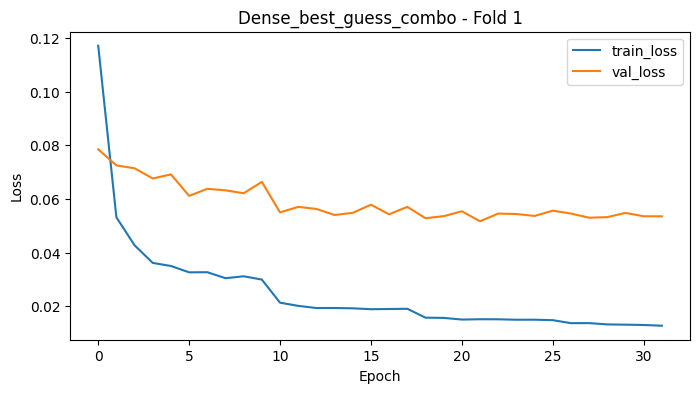

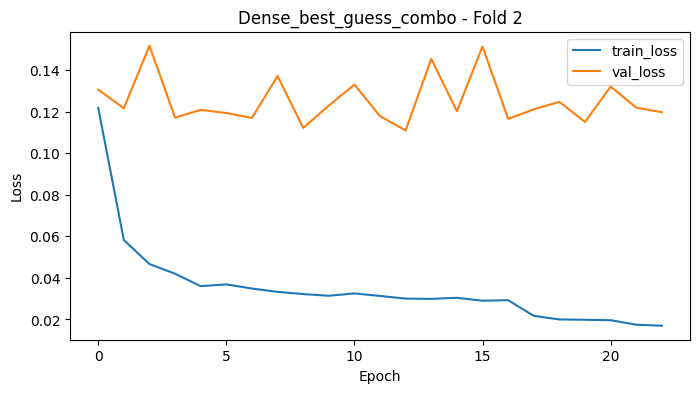

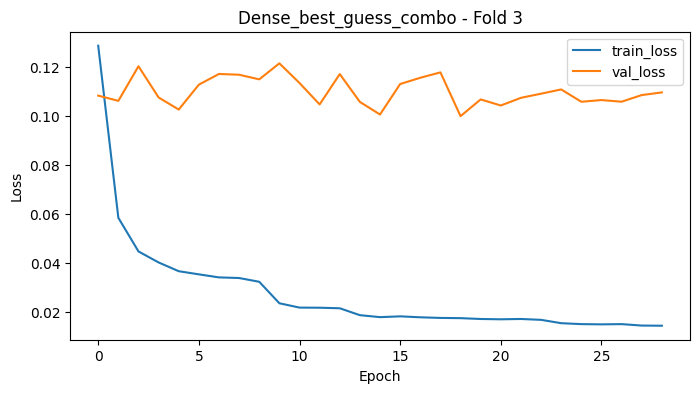

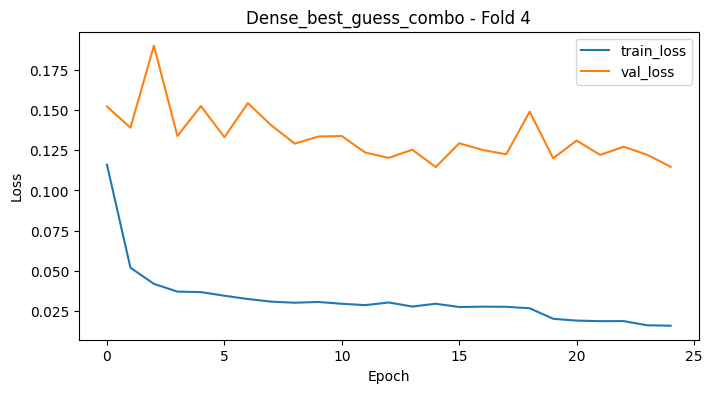

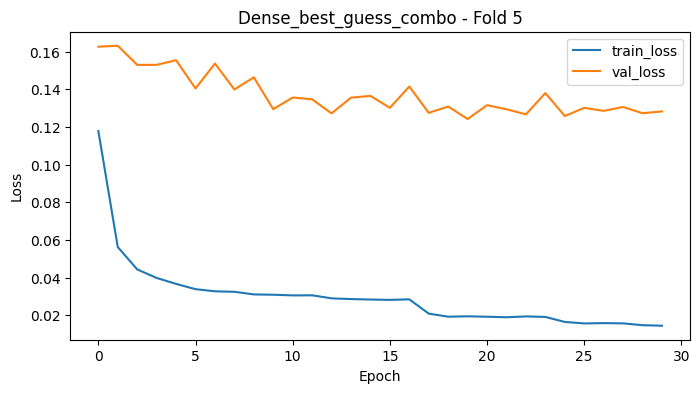

In [29]:
def plot_history(history, title):
    plt.figure(figsize=(8, 4))
    plt.plot(history["train_loss"], label="train_loss")
    plt.plot(history["val_loss"], label="val_loss")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

champion_histories = all_dense_histories[dense_champion_variant]
for fold_idx, hist in enumerate(champion_histories, start=1):
    plot_history(hist, f"{dense_champion_variant} - Fold {fold_idx}")

### Per-joint error for the optimized champion

,joint,mean_error_cm,std_error_cm
7,left_hip,2.789293,0.410485
8,right_hip,2.813567,0.402646
1,left_shoulder,2.834545,0.306594
11,left_foot,2.875252,0.366957
12,right_foot,2.934370,0.616025
3,right_shoulder,2.962304,0.358072
9,left_knee,3.007881,0.470532
10,right_knee,3.077623,0.403579
0,head,3.334933,0.484104
2,left_elbow,3.881489,0.353381


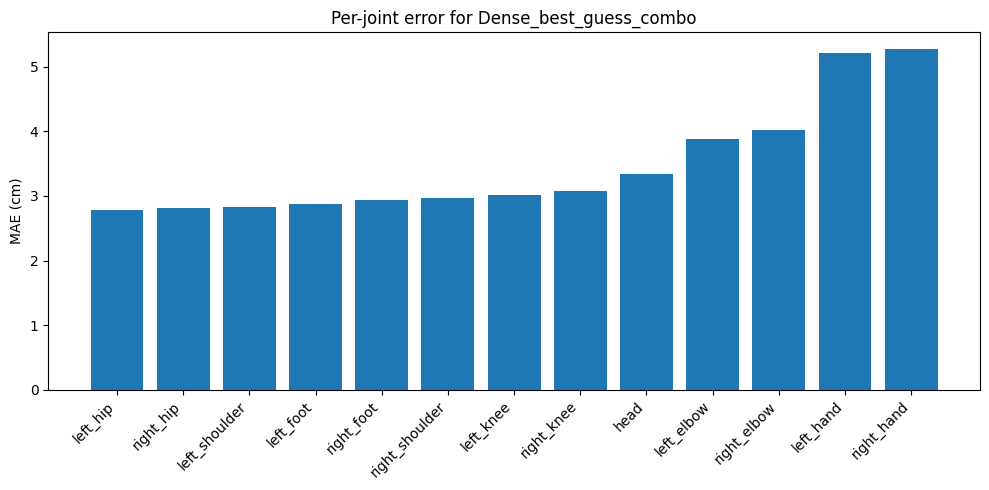

In [30]:
dense_champion_fold_df = dense_results_folds[
    dense_results_folds["model_variant"] == dense_champion_variant
].copy()

joint_mae_matrix = np.array(dense_champion_fold_df["joint_mae_cm"].tolist())

dense_joint_summary = pd.DataFrame({
    "joint": JOINTS,
    "mean_error_cm": joint_mae_matrix.mean(axis=0),
    "std_error_cm": joint_mae_matrix.std(axis=0),
}).sort_values("mean_error_cm", ascending=True)

display(dense_joint_summary)

plt.figure(figsize=(10, 5))
plt.bar(dense_joint_summary["joint"], dense_joint_summary["mean_error_cm"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("MAE (cm)")
plt.title(f"Per-joint error for {dense_champion_variant}")
plt.tight_layout()
plt.show()

### See which setup choices helped most

In [31]:
analysis_df = dense_results_folds.copy()

display(
    analysis_df.groupby("optimizer", as_index=False)["test_mae_cm"].mean().sort_values("test_mae_cm")
)

display(
    analysis_df.groupby("loss_name", as_index=False)["test_mae_cm"].mean().sort_values("test_mae_cm")
)

display(
    analysis_df.groupby("use_velocity", as_index=False)["test_mae_cm"].mean().sort_values("test_mae_cm")
)

display(
    analysis_df.groupby("scale_targets", as_index=False)["test_mae_cm"].mean().sort_values("test_mae_cm")
)

display(
    analysis_df.groupby("clip_targets", as_index=False)["test_mae_cm"].mean().sort_values("test_mae_cm")
)

display(
    analysis_df.groupby("seq_len", as_index=False)["test_mae_cm"].mean().sort_values("test_mae_cm")
)

,optimizer,test_mae_cm
1,adamw,3.558745
0,adam,3.705886


,loss_name,test_mae_cm
0,huber,3.631341
1,mse,3.689754


,use_velocity,test_mae_cm
1,True,3.637109
0,False,3.688472


,scale_targets,test_mae_cm
1,True,3.465289
0,False,3.726654


,clip_targets,test_mae_cm
1,True,3.568350
0,False,3.690212


,seq_len,test_mae_cm
0,20,3.665336
1,30,3.817110


### Save results

In [32]:
dense_fold_results_path = output_dir / "A9_optimize_dense_cv_folds.csv"
dense_summary_results_path = output_dir / "A9_optimize_dense_cv_summary.csv"
dense_joint_results_path = output_dir / "A9_optimize_dense_joint_summary.csv"

dense_results_folds.to_csv(dense_fold_results_path, index=False)
dense_results_summary.to_csv(dense_summary_results_path, index=False)
dense_joint_summary.to_csv(dense_joint_results_path, index=False)

print(f"Saved fold results to: {dense_fold_results_path}")
print(f"Saved summary results to: {dense_summary_results_path}")
print(f"Saved joint summary to: {dense_joint_results_path}")

Saved fold results to: reporting\results\A9_optimize_dense_cv_folds.csv
Saved summary results to: reporting\results\A9_optimize_dense_cv_summary.csv
Saved joint summary to: reporting\results\A9_optimize_dense_joint_summary.csv


## Second round of champion model

In [ ]:
# Focused follow-up tuning around the current Dense champion

focused_dense_configs = [
    {
        "model_variant": "Dense_focus_dropout015",
        "hidden_units": (512, 256, 128),
        "dropout_rate": 0.15,
        "activation": "gelu",
        "optimizer": "adamw",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 32,
        "loss_name": "huber",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": True,
        "clip_targets": False,
        "scale_targets": True,
    },
    {
        "model_variant": "Dense_focus_dropout020",
        "hidden_units": (512, 256, 128),
        "dropout_rate": 0.20,
        "activation": "gelu",
        "optimizer": "adamw",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 32,
        "loss_name": "huber",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": True,
        "clip_targets": False,
        "scale_targets": True,
    },
    {
        "model_variant": "Dense_focus_dropout025",
        "hidden_units": (512, 256, 128),
        "dropout_rate": 0.25,
        "activation": "gelu",
        "optimizer": "adamw",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 32,
        "loss_name": "huber",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": True,
        "clip_targets": False,
        "scale_targets": True,
    },
    {
        "model_variant": "Dense_focus_wd5e4",
        "hidden_units": (512, 256, 128),
        "dropout_rate": 0.10,
        "activation": "gelu",
        "optimizer": "adamw",
        "learning_rate": 1e-3,
        "weight_decay": 5e-4,
        "batch_size": 32,
        "loss_name": "huber",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": True,
        "clip_targets": False,
        "scale_targets": True,
    },
    {
        "model_variant": "Dense_focus_wd1e3",
        "hidden_units": (512, 256, 128),
        "dropout_rate": 0.10,
        "activation": "gelu",
        "optimizer": "adamw",
        "learning_rate": 1e-3,
        "weight_decay": 1e-3,
        "batch_size": 32,
        "loss_name": "huber",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": True,
        "clip_targets": False,
        "scale_targets": True,
    },
    {
        "model_variant": "Dense_focus_lr5e4",
        "hidden_units": (512, 256, 128),
        "dropout_rate": 0.10,
        "activation": "gelu",
        "optimizer": "adamw",
        "learning_rate": 5e-4,
        "weight_decay": 1e-4,
        "batch_size": 32,
        "loss_name": "huber",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": True,
        "clip_targets": False,
        "scale_targets": True,
    },
    {
        "model_variant": "Dense_focus_lr7e4",
        "hidden_units": (512, 256, 128),
        "dropout_rate": 0.10,
        "activation": "gelu",
        "optimizer": "adamw",
        "learning_rate": 7e-4,
        "weight_decay": 1e-4,
        "batch_size": 32,
        "loss_name": "huber",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": True,
        "clip_targets": False,
        "scale_targets": True,
    },
    {
        "model_variant": "Dense_focus_smaller_384_192_96",
        "hidden_units": (384, 192, 96),
        "dropout_rate": 0.10,
        "activation": "gelu",
        "optimizer": "adamw",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 32,
        "loss_name": "huber",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": True,
        "clip_targets": False,
        "scale_targets": True,
    },
    {
        "model_variant": "Dense_focus_smaller_256_128_64",
        "hidden_units": (256, 128, 64),
        "dropout_rate": 0.10,
        "activation": "gelu",
        "optimizer": "adamw",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 32,
        "loss_name": "huber",
        "use_scheduler": True,
        "seq_len": 20,
        "stride": 1,
        "use_velocity": True,
        "clip_targets": False,
        "scale_targets": True,
    },
]

focused_fold_results = []
focused_histories = {}

for config in focused_dense_configs:
    print(f"Running {config['model_variant']} ...")
    fold_results, fold_histories = run_dense_cv_experiment(df_raw, config)
    focused_fold_results.extend(fold_results)
    focused_histories[config["model_variant"]] = fold_histories

focused_results_folds = pd.DataFrame(focused_fold_results)

focused_results_summary = (
    focused_results_folds
    .groupby(["model_family", "model_variant"], as_index=False)
    .agg(
        mean_test_mae=("test_mae", "mean"),
        std_test_mae=("test_mae", "std"),
        mean_test_mae_cm=("test_mae_cm", "mean"),
        std_test_mae_cm=("test_mae_cm", "std"),
        mean_best_val_loss=("best_val_loss", "mean"),
        mean_best_epoch=("best_epoch", "mean"),
    )
    .sort_values("mean_test_mae_cm", ascending=True)
    .reset_index(drop=True)
)

display(focused_results_summary)

best_focused = focused_results_summary.iloc[0]
print("Best focused variant:", best_focused["model_variant"])
print(f"Mean CV test MAE in cm: {best_focused['mean_test_mae_cm']:.3f} cm")
print(f"Std CV test MAE in cm: {best_focused['std_test_mae_cm']:.3f} cm")

Running Dense_focus_dropout015 ...
🏃 View run Dense_focus_dropout015 at: https://172.27.62.170:5001/#/experiments/22/runs/903daf6678804b339a01017ec1c2d781
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Dense_focus_dropout020 ...
🏃 View run Dense_focus_dropout020 at: https://172.27.62.170:5001/#/experiments/22/runs/1475cb59b5e5476e9d5a3555101a1daf
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Dense_focus_dropout025 ...
🏃 View run Dense_focus_dropout025 at: https://172.27.62.170:5001/#/experiments/22/runs/51f1643e6e6d497697d4b2abd413c4de
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Dense_focus_wd5e4 ...
🏃 View run Dense_focus_wd5e4 at: https://172.27.62.170:5001/#/experiments/22/runs/1a14e289e7504478971a13d4fe36bd25
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Dense_focus_wd1e3 ...
🏃 View run Dense_focus_wd1e3 at: https://172.27.62.170:5001/#/experiments/22/runs/416f498bb75045

,model_family,model_variant,mean_test_mae,std_test_mae,mean_test_mae_cm,std_test_mae_cm,mean_best_val_loss,mean_best_epoch
0,Dense,Dense_focus_dropout025,0.034090,0.003956,3.408983,0.395553,0.094033,28.8
1,Dense,Dense_focus_lr5e4,0.034240,0.004295,3.423971,0.429507,0.096792,12.4
2,Dense,Dense_focus_lr7e4,0.034402,0.004313,3.440222,0.431298,0.094443,20.6
3,Dense,Dense_focus_dropout015,0.034626,0.003818,3.462562,0.381767,0.098528,21.6
4,Dense,Dense_focus_dropout020,0.034654,0.004797,3.465353,0.479726,0.102866,18.8
5,Dense,Dense_focus_wd1e3,0.034766,0.004377,3.476617,0.437733,0.098929,15.8
6,Dense,Dense_focus_smaller_384_192_96,0.034776,0.003507,3.477589,0.350672,0.099722,13.0
7,Dense,Dense_focus_wd5e4,0.035157,0.004448,3.515660,0.444849,0.097890,11.4
8,Dense,Dense_focus_smaller_256_128_64,0.035664,0.005102,3.566350,0.510172,0.097399,18.2


Best focused variant: Dense_focus_dropout025
Mean CV test MAE in cm: 3.409 cm
Std CV test MAE in cm: 0.396 cm


### Save Dense_best_combo to MLFlow

In [ ]:
# Save and package the current Dense champion so it can be promoted later

import json
import joblib
from datetime import datetime

champion_config = {
    "model_variant": "Dense_best_guess_combo",
    "hidden_units": (512, 256, 128),
    "dropout_rate": 0.10,
    "activation": "gelu",
    "optimizer": "adamw",
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "batch_size": 32,
    "loss_name": "huber",
    "use_scheduler": True,
    "seq_len": 20,
    "stride": 1,
    "use_velocity": True,
    "clip_targets": False,
    "scale_targets": True,
}

# 1) Prepare full dataset using the champion data handling
prepared = prepare_dense_dataset(
    df_raw=df_raw,
    seq_len=champion_config["seq_len"],
    stride=champion_config["stride"],
    use_velocity=champion_config["use_velocity"],
    clip_targets=champion_config["clip_targets"],
)

X = prepared["X"]
y = prepared["y"]
seq_ids = prepared["seq_ids"]
input_cols = prepared["input_cols"]

# 2) Create one train/validation split across full available data for final packaging
unique_sequences = np.unique(seq_ids)
train_seq_ids, val_seq_ids = train_test_split(
    unique_sequences,
    test_size=VALIDATION_SPLIT,
    random_state=RANDOM_SEED,
)

train_mask = np.isin(seq_ids, train_seq_ids)
val_mask = np.isin(seq_ids, val_seq_ids)

X_train = X[train_mask]
y_train = y[train_mask]
X_val = X[val_mask]
y_val = y[val_mask]

# 3) Fit scalers on training data only
x_scaler = fit_scaler_on_training_sequences(X_train)
X_train_scaled = transform_sequences(X_train, x_scaler)
X_val_scaled = transform_sequences(X_val, x_scaler)

y_scaler = None
if champion_config["scale_targets"]:
    y_scaler = fit_target_scaler_on_training_sequences(y_train)
    y_train_scaled = transform_targets(y_train, y_scaler)
    y_val_scaled = transform_targets(y_val, y_scaler)
else:
    y_train_scaled = y_train.astype(np.float32)
    y_val_scaled = y_val.astype(np.float32)

# 4) DataLoaders
train_dataset = SequenceDataset(X_train_scaled, y_train_scaled)
val_dataset = SequenceDataset(X_val_scaled, y_val_scaled)

train_loader = DataLoader(train_dataset, batch_size=champion_config["batch_size"], shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=champion_config["batch_size"], shuffle=False)

# 5) Build and train champion model
champion_model = DenseDepthRegressorFlexible(
    seq_len=champion_config["seq_len"],
    n_features=len(input_cols),
    n_targets=len(TARGET_FEATURES),
    hidden_units=champion_config["hidden_units"],
    dropout_rate=champion_config["dropout_rate"],
    activation=champion_config["activation"],
)

champion_model, champion_history, champion_best_val_loss, champion_best_epoch = train_model_flexible(
    model=champion_model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer_name=champion_config["optimizer"],
    lr=champion_config["learning_rate"],
    weight_decay=champion_config["weight_decay"],
    loss_name=champion_config["loss_name"],
    epochs=EPOCHS,
    patience=PATIENCE,
    use_scheduler=champion_config["use_scheduler"],
)

# 6) Evaluate validation MAE
val_eval_dataset = SequenceDataset(X_val_scaled, y_val.astype(np.float32))
val_eval_loader = DataLoader(val_eval_dataset, batch_size=champion_config["batch_size"], shuffle=False)

y_val_true, y_val_pred = predict_model(champion_model, val_eval_loader)

if y_scaler is not None:
    y_val_pred = inverse_transform_targets(y_val_pred, y_scaler)

val_mae = mean_absolute_error(
    y_val_true.reshape(-1, y_val_true.shape[-1]),
    y_val_pred.reshape(-1, y_val_pred.shape[-1]),
)
val_mae_cm = to_cm(val_mae)

# 7) Save everything needed for later promotion/inference
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
champion_dir = output_dir / f"dense_champion_{timestamp}"
champion_dir.mkdir(parents=True, exist_ok=True)

model_path = champion_dir / "dense_champion_state_dict.pt"
x_scaler_path = champion_dir / "input_scaler.joblib"
y_scaler_path = champion_dir / "target_scaler.joblib"
config_path = champion_dir / "champion_config.json"
metadata_path = champion_dir / "champion_metadata.json"
history_path = champion_dir / "training_history.json"

torch.save(champion_model.state_dict(), model_path)
joblib.dump(x_scaler, x_scaler_path)

if y_scaler is not None:
    joblib.dump(y_scaler, y_scaler_path)

champion_config_json = champion_config.copy()
champion_config_json["hidden_units"] = list(champion_config_json["hidden_units"])

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(champion_config_json, f, indent=2)

champion_metadata = {
    "model_family": "Dense",
    "model_variant": champion_config["model_variant"],
    "saved_at": timestamp,
    "device_used": str(DEVICE),
    "n_input_features": len(input_cols),
    "input_columns": input_cols,
    "target_columns": TARGET_FEATURES,
    "target_unit": TARGET_UNIT,
    "seq_len": champion_config["seq_len"],
    "stride": champion_config["stride"],
    "use_velocity": champion_config["use_velocity"],
    "clip_targets": champion_config["clip_targets"],
    "scale_targets": champion_config["scale_targets"],
    "best_val_loss": float(champion_best_val_loss),
    "best_epoch": int(champion_best_epoch),
    "val_mae": float(val_mae),
    "val_mae_cm": float(val_mae_cm),
    "n_train_sequences": int(len(X_train)),
    "n_val_sequences": int(len(X_val)),
    "model_class": "DenseDepthRegressorFlexible",
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(champion_metadata, f, indent=2)

serializable_history = {
    k: [float(v) for v in values]
    for k, values in champion_history.items()
}
with open(history_path, "w", encoding="utf-8") as f:
    json.dump(serializable_history, f, indent=2)

# 8) Log packaged champion to MLflow
with mlflow.start_run(run_name=f"{champion_config['model_variant']}_packaged", nested=False):
    mlflow.log_param("model_family", "Dense")
    mlflow.log_param("model_variant", champion_config["model_variant"])
    mlflow.log_param("packaged_for_promotion", True)
    mlflow.log_param("seq_len", champion_config["seq_len"])
    mlflow.log_param("stride", champion_config["stride"])
    mlflow.log_param("use_velocity", champion_config["use_velocity"])
    mlflow.log_param("scale_targets", champion_config["scale_targets"])
    mlflow.log_param("optimizer", champion_config["optimizer"])
    mlflow.log_param("loss_name", champion_config["loss_name"])

    mlflow.log_metric("best_val_loss", float(champion_best_val_loss))
    mlflow.log_metric("best_epoch", int(champion_best_epoch))
    mlflow.log_metric("val_mae", float(val_mae))
    mlflow.log_metric("val_mae_cm", float(val_mae_cm))

    mlflow.log_artifact(str(model_path))
    mlflow.log_artifact(str(x_scaler_path))
    if y_scaler is not None:
        mlflow.log_artifact(str(y_scaler_path))
    mlflow.log_artifact(str(config_path))
    mlflow.log_artifact(str(metadata_path))
    mlflow.log_artifact(str(history_path))

print("Champion package saved.")
print("Folder:", champion_dir)
print("Model:", model_path)
print("Input scaler:", x_scaler_path)
print("Target scaler:", y_scaler_path if y_scaler is not None else "None")
print("Config:", config_path)
print("Metadata:", metadata_path)
print("History:", history_path)
print(f"Best validation loss: {champion_best_val_loss:.6f}")
print(f"Best epoch: {champion_best_epoch}")
print(f"Validation MAE: {val_mae:.6f}")
print(f"Validation MAE (cm): {val_mae_cm:.3f} cm")

🏃 View run Dense_best_guess_combo_packaged at: https://172.27.62.170:5001/#/experiments/22/runs/83e6cc102967420d9f0f59e457b66423
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Champion package saved.
Folder: reporting\results\dense_champion_20260415_053339
Model: reporting\results\dense_champion_20260415_053339\dense_champion_state_dict.pt
Input scaler: reporting\results\dense_champion_20260415_053339\input_scaler.joblib
Target scaler: reporting\results\dense_champion_20260415_053339\target_scaler.joblib
Config: reporting\results\dense_champion_20260415_053339\champion_config.json
Metadata: reporting\results\dense_champion_20260415_053339\champion_metadata.json
History: reporting\results\dense_champion_20260415_053339\training_history.json
Best validation loss: 0.073610
Best epoch: 27
Validation MAE: 0.028876
Validation MAE (cm): 2.888 cm


In [33]:
# Log the cross-validated champion performance for promotion tracking

cv_champion_variant = "Dense_best_guess_combo"

cv_champion_row = dense_results_summary[
    dense_results_summary["model_variant"] == cv_champion_variant
].iloc[0]

cv_mean_test_mae = float(cv_champion_row["mean_test_mae"])
cv_std_test_mae = float(cv_champion_row["std_test_mae"])
cv_mean_test_mae_cm = float(cv_champion_row["mean_test_mae_cm"])
cv_std_test_mae_cm = float(cv_champion_row["std_test_mae_cm"])
cv_mean_best_val_loss = float(cv_champion_row["mean_best_val_loss"])
cv_mean_best_epoch = float(cv_champion_row["mean_best_epoch"])

with mlflow.start_run(run_name=f"{cv_champion_variant}_promotion_summary", nested=False):
    mlflow.log_param("model_family", "Dense")
    mlflow.log_param("model_variant", cv_champion_variant)
    mlflow.log_param("promotion_candidate", True)
    mlflow.log_param("metric_source", "cross_validated_experiment_summary")

    mlflow.log_metric("cv_mean_test_mae", cv_mean_test_mae)
    mlflow.log_metric("cv_std_test_mae", cv_std_test_mae)
    mlflow.log_metric("cv_mean_test_mae_cm", cv_mean_test_mae_cm)
    mlflow.log_metric("cv_std_test_mae_cm", cv_std_test_mae_cm)
    mlflow.log_metric("cv_mean_best_val_loss", cv_mean_best_val_loss)
    mlflow.log_metric("cv_mean_best_epoch", cv_mean_best_epoch)

print("Logged CV promotion summary to MLflow.")
print("Model variant:", cv_champion_variant)
print(f"CV mean test MAE: {cv_mean_test_mae:.6f}")
print(f"CV mean test MAE (cm): {cv_mean_test_mae_cm:.3f} cm")
print(f"CV std test MAE (cm): {cv_std_test_mae_cm:.3f} cm")

🏃 View run Dense_best_guess_combo_promotion_summary at: https://172.27.62.170:5001/#/experiments/22/runs/51bda6d530754669a521ae557d818363
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Logged CV promotion summary to MLflow.
Model variant: Dense_best_guess_combo
CV mean test MAE: 0.034622
CV mean test MAE (cm): 3.462 cm
CV std test MAE (cm): 0.430 cm


In [ ]:
# Diagnostic summary for Dense optimization results

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# 1. Main leaderboard
print("=" * 100)
print("LEADERBOARD — sorted by mean_test_mae_cm")
print("=" * 100)

leaderboard_cols = [
    "model_variant",
    "mean_test_mae_cm",
    "std_test_mae_cm",
    "mean_test_mae",
    "std_test_mae",
    "mean_best_val_loss",
    "mean_best_epoch",
]

display(dense_results_summary[leaderboard_cols].sort_values("mean_test_mae_cm").reset_index(drop=True))


# 2. Fold-level spread for best few models
print("\n" + "=" * 100)
print("FOLD-LEVEL RESULTS — best 5 variants")
print("=" * 100)

top_variants = dense_results_summary.sort_values("mean_test_mae_cm").head(5)["model_variant"].tolist()

fold_view = dense_results_folds[
    dense_results_folds["model_variant"].isin(top_variants)
].copy()

fold_view = fold_view[
    [
        "model_variant",
        "fold",
        "test_mae_cm",
        "best_val_loss",
        "best_epoch",
        "optimizer",
        "learning_rate",
        "loss_name",
        "batch_size",
        "seq_len",
        "stride",
        "use_velocity",
        "clip_targets",
        "scale_targets",
    ]
].sort_values(["model_variant", "fold"])

display(fold_view.reset_index(drop=True))


# 3. Approximate overfitting signal from training histories
print("\n" + "=" * 100)
print("OVERFITTING CHECK — final train/val loss gap per fold")
print("=" * 100)

overfit_rows = []

for variant, histories in all_dense_histories.items():
    for fold_idx, hist in enumerate(histories, start=1):
        final_train_loss = hist["train_loss"][-1]
        final_val_loss = hist["val_loss"][-1]
        min_val_loss = min(hist["val_loss"])
        best_epoch = int(np.argmin(hist["val_loss"]) + 1)

        overfit_gap = final_val_loss - final_train_loss
        val_rebound = final_val_loss - min_val_loss

        overfit_rows.append({
            "model_variant": variant,
            "fold": fold_idx,
            "final_train_loss": float(final_train_loss),
            "final_val_loss": float(final_val_loss),
            "min_val_loss": float(min_val_loss),
            "best_epoch_from_curve": best_epoch,
            "overfit_gap_final_val_minus_train": float(overfit_gap),
            "val_rebound_final_minus_best": float(val_rebound),
            "epochs_ran": len(hist["train_loss"]),
        })

overfit_df = pd.DataFrame(overfit_rows)

overfit_summary = (
    overfit_df.groupby("model_variant", as_index=False)
    .agg(
        mean_final_train_loss=("final_train_loss", "mean"),
        mean_final_val_loss=("final_val_loss", "mean"),
        mean_min_val_loss=("min_val_loss", "mean"),
        mean_overfit_gap=("overfit_gap_final_val_minus_train", "mean"),
        mean_val_rebound=("val_rebound_final_minus_best", "mean"),
        mean_epochs_ran=("epochs_ran", "mean"),
    )
    .merge(
        dense_results_summary[["model_variant", "mean_test_mae_cm"]],
        on="model_variant",
        how="left",
    )
    .sort_values("mean_test_mae_cm")
    .reset_index(drop=True)
)

display(overfit_summary)


# 4. Show only the champion's overfitting details
print("\n" + "=" * 100)
print("CHAMPION OVERFITTING DETAILS")
print("=" * 100)

champion_variant = dense_results_summary.sort_values("mean_test_mae_cm").iloc[0]["model_variant"]
champion_overfit = overfit_df[overfit_df["model_variant"] == champion_variant].copy()

print("Champion:", champion_variant)
display(champion_overfit.reset_index(drop=True))


# 5. Which choices helped on average
print("\n" + "=" * 100)
print("AVERAGE EFFECT OF CHOICES")
print("=" * 100)

display(
    dense_results_folds.groupby("optimizer", as_index=False)["test_mae_cm"]
    .mean()
    .sort_values("test_mae_cm")
    .reset_index(drop=True)
)

display(
    dense_results_folds.groupby("loss_name", as_index=False)["test_mae_cm"]
    .mean()
    .sort_values("test_mae_cm")
    .reset_index(drop=True)
)

display(
    dense_results_folds.groupby("use_velocity", as_index=False)["test_mae_cm"]
    .mean()
    .sort_values("test_mae_cm")
    .reset_index(drop=True)
)

display(
    dense_results_folds.groupby("scale_targets", as_index=False)["test_mae_cm"]
    .mean()
    .sort_values("test_mae_cm")
    .reset_index(drop=True)
)

display(
    dense_results_folds.groupby("clip_targets", as_index=False)["test_mae_cm"]
    .mean()
    .sort_values("test_mae_cm")
    .reset_index(drop=True)
)

display(
    dense_results_folds.groupby("seq_len", as_index=False)["test_mae_cm"]
    .mean()
    .sort_values("test_mae_cm")
    .reset_index(drop=True)
)



LEADERBOARD — sorted by mean_test_mae_cm


,model_variant,mean_test_mae_cm,std_test_mae_cm,mean_test_mae,std_test_mae,mean_best_val_loss,mean_best_epoch
0,Dense_best_guess_combo,3.372995,0.412741,0.033730,0.004127,0.099250,19.2
1,Dense_target_scaled,3.488941,0.537682,0.034889,0.005377,0.279847,9.6
2,Dense_adamw_weightdecay,3.574974,0.630203,0.035750,0.006302,0.002300,21.4
3,Dense_clip_targets_1_99,3.585124,0.408317,0.035851,0.004083,0.002090,16.0
4,Dense_stride2,3.623514,0.357854,0.036235,0.003579,0.002947,14.2
5,Dense_wider_512_256_128,3.628473,0.578484,0.036285,0.005785,0.002288,10.2
6,Dense_with_velocity,3.743215,0.503202,0.037432,0.005032,0.002362,22.8
7,Dense_huber_loss,3.745853,0.395675,0.037459,0.003957,0.001181,16.8
8,Dense_seq30,3.803517,0.535516,0.038035,0.005355,0.002394,14.0
9,Dense_dropout_256_128_do02,3.852417,0.413837,0.038524,0.004138,0.002393,18.6



FOLD-LEVEL RESULTS — best 5 variants


,model_variant,fold,test_mae_cm,best_val_loss,best_epoch,optimizer,learning_rate,loss_name,batch_size,seq_len,stride,use_velocity,clip_targets,scale_targets
0,Dense_adamw_weightdecay,1,4.333823,0.001127,42,adamw,0.001,mse,32,20,1,False,False,False
1,Dense_adamw_weightdecay,2,3.197376,0.002823,16,adamw,0.001,mse,32,20,1,False,False,False
2,Dense_adamw_weightdecay,3,2.927106,0.001822,24,adamw,0.001,mse,32,20,1,False,False,False
3,Dense_adamw_weightdecay,4,4.163756,0.003179,3,adamw,0.001,mse,32,20,1,False,False,False
4,Dense_adamw_weightdecay,5,3.252808,0.002548,22,adamw,0.001,mse,32,20,1,False,False,False
5,Dense_best_guess_combo,1,3.945917,0.050776,31,adamw,0.001,huber,32,20,1,True,False,True
6,Dense_best_guess_combo,2,3.096353,0.108289,24,adamw,0.001,huber,32,20,1,True,False,True
7,Dense_best_guess_combo,3,3.001018,0.104300,10,adamw,0.001,huber,32,20,1,True,False,True
8,Dense_best_guess_combo,4,3.671055,0.107896,9,adamw,0.001,huber,32,20,1,True,False,True
9,Dense_best_guess_combo,5,3.150633,0.124991,22,adamw,0.001,huber,32,20,1,True,False,True



OVERFITTING CHECK — final train/val loss gap per fold


,model_variant,mean_final_train_loss,mean_final_val_loss,mean_min_val_loss,mean_overfit_gap,mean_val_rebound,mean_epochs_ran,mean_test_mae_cm
0,Dense_best_guess_combo,0.014386,0.105969,0.099250,0.091584,0.006719,29.2,3.372995
1,Dense_target_scaled,0.045327,0.301557,0.279847,0.256230,0.021710,19.6,3.488941
2,Dense_adamw_weightdecay,0.000797,0.002656,0.002300,0.001859,0.000356,31.4,3.574974
3,Dense_clip_targets_1_99,0.000742,0.002298,0.002090,0.001556,0.000207,26.0,3.585124
4,Dense_stride2,0.000928,0.003136,0.002947,0.002208,0.000189,24.2,3.623514
5,Dense_wider_512_256_128,0.000236,0.002879,0.002288,0.002643,0.000591,20.2,3.628473
6,Dense_with_velocity,0.001048,0.002520,0.002362,0.001472,0.000158,32.8,3.743215
7,Dense_huber_loss,0.000420,0.001298,0.001181,0.000877,0.000117,26.8,3.745853
8,Dense_seq30,0.001027,0.002629,0.002394,0.001602,0.000236,24.0,3.803517
9,Dense_dropout_256_128_do02,0.001722,0.002778,0.002393,0.001056,0.000385,28.6,3.852417


... (5 outputs left out)

,use_velocity,test_mae_cm
0,True,3.558105
1,False,3.684726


,scale_targets,test_mae_cm
0,True,3.430968
1,False,3.712978


,clip_targets,test_mae_cm
0,True,3.585124
1,False,3.669362


,seq_len,test_mae_cm
0,20,3.647522
1,30,3.803517
